In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Option pour afficher toutes les colonnes
pd.set_option('display.max_columns', None)

In [ ]:
# Lien pour le taux hypothécaire 30 ans (Hebdomadaire)
url_mortgage = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=MORTGAGE30US"

# Lien pour le taux à 10 ans (Quotidien)
url_dgs10 = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"

# Chargement des données dans Pandas
df_mortgage = pd.read_csv(url_mortgage)
df_dgs10 = pd.read_csv(url_dgs10)

In [ ]:
print("--- TAUX HYPOTHÉCAIRE ---")
print(df_mortgage.head()) # Affiche les 5 premières lignes
print(df_mortgage.info()) # Affiche le type des données et s'il y a des valeurs manquantes

print("\n--- TAUX A 10 ANS ---")
print(df_dgs10.head())
print(df_dgs10.info())

--- TAUX HYPOTHÉCAIRE ---
  observation_date  MORTGAGE30US
0       1971-04-02          7.33
1       1971-04-09          7.31
2       1971-04-16          7.31
3       1971-04-23          7.31
4       1971-04-30          7.29
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2902 entries, 0 to 2901
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  2902 non-null   object 
 1   MORTGAGE30US      2902 non-null   float64
dtypes: float64(1), object(1)
memory usage: 45.5+ KB
None

--- TAUX A 10 ANS ---
  observation_date  DGS10
0       1962-01-02   4.06
1       1962-01-03   4.03
2       1962-01-04   3.99
3       1962-01-05   4.02
4       1962-01-08   4.03
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16917 entries, 0 to 16916
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  16917 non-null  obje

In [ ]:
# 1. Vérifier le nom exact de la colonne de date (regarde le résultat de l'étape 4)
# Supposons qu'elle s'appelle 'observation_date' ou 'DATE'. Adapte le code ci-dessous :

# Pour le taux hypothécaire
colonne_date_mortgage = df_mortgage.columns[0] # Prend la première colonne
df_mortgage[colonne_date_mortgage] = pd.to_datetime(df_mortgage[colonne_date_mortgage])
df_mortgage.set_index(colonne_date_mortgage, inplace=True) # On met la date en index

# Pour le taux à 10 ans
colonne_date_dgs10 = df_dgs10.columns[0]
df_dgs10[colonne_date_dgs10] = pd.to_datetime(df_dgs10[colonne_date_dgs10])
df_dgs10.set_index(colonne_date_dgs10, inplace=True)

# 2. Renommer les colonnes pour que ce soit plus clair (souvent la colonne s'appelle MORTGAGE30US ou DGS10)
df_mortgage.columns = ['Taux_30ans']
df_dgs10.columns = ['Taux_10ans']

# 3. Vérifier que c'est bien propre
print("--- TAUX HYPOTHÉCAIRE (Propre) ---")
print(df_mortgage.head())
print("\n--- TAUX A 10 ANS (Propre) ---")
print(df_dgs10.head())

--- TAUX HYPOTHÉCAIRE (Propre) ---
                  Taux_30ans
observation_date            
1971-04-02              7.33
1971-04-09              7.31
1971-04-16              7.31
1971-04-23              7.31
1971-04-30              7.29

--- TAUX A 10 ANS (Propre) ---
                  Taux_10ans
observation_date            
1962-01-02              4.06
1962-01-03              4.03
1962-01-04              3.99
1962-01-05              4.02
1962-01-08              4.03


In [ ]:
# Remplace les '.' par des NaN (valeurs manquantes)
df_mortgage = df_mortgage.replace('.', np.nan)
df_dgs10 = df_dgs10.replace('.', np.nan)

# Convertit les colonnes en nombres (float) au cas où
df_mortgage['Taux_30ans'] = pd.to_numeric(df_mortgage['Taux_30ans'], errors='coerce')
df_dgs10['Taux_10ans'] = pd.to_numeric(df_dgs10['Taux_10ans'], errors='coerce')

# Supprime les lignes où il n'y a pas de données
df_mortgage = df_mortgage.dropna()
df_dgs10 = df_dgs10.dropna()

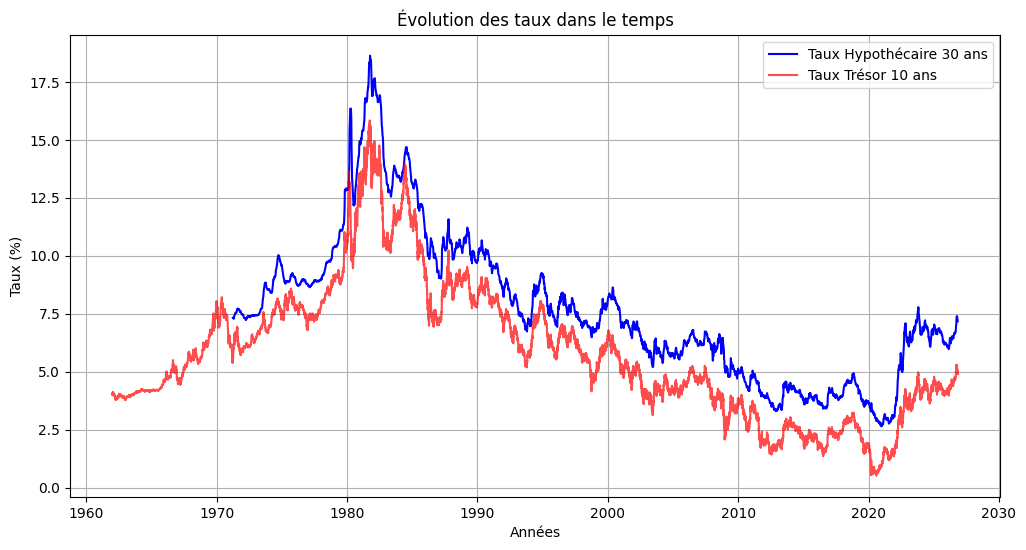

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df_mortgage.index, df_mortgage['Taux_30ans'], label='Taux Hypothécaire 30 ans', color='blue')
plt.plot(df_dgs10.index, df_dgs10['Taux_10ans'], label='Taux Trésor 10 ans', color='red', alpha=0.7)
plt.title('Évolution des taux dans le temps')
plt.xlabel('Années')
plt.ylabel('Taux (%)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# On regroupe les données quotidiennes du taux 10 ans par semaine ('W' pour Weekly)
# et on prend la moyenne de la semaine.
df_dgs10_hebdo = df_dgs10.resample('W').mean()

# Vérifions la taille (on devrait passer de ~15000 lignes à ~3000 lignes)
print("Taille taux 10 ans original :", df_dgs10.shape)
print("Taille taux 10 ans hebdo :", df_dgs10_hebdo.shape)

Taille taux 10 ans original : (16196, 1)
Taille taux 10 ans hebdo : (3384, 1)


In [ ]:
# On remet les dates en colonnes pour pouvoir faire le merge_asof
df_mortgage_reset = df_mortgage.reset_index()
df_dgs10_hebdo_reset = df_dgs10_hebdo.reset_index()

# merge_asof permet de joindre sur la date la plus proche
# On trie d'abord les données par date (obligatoire pour cette fonction)
df_mortgage_reset = df_mortgage_reset.sort_values(by='observation_date')
df_dgs10_hebdo_reset = df_dgs10_hebdo_reset.sort_values(by='observation_date')

df_final = pd.merge_asof(
    df_mortgage_reset,
    df_dgs10_hebdo_reset,
    on='observation_date',
    direction='nearest' # Prend la date la plus proche
)

# On remet la date en index
df_final.set_index('observation_date', inplace=True)

print("Nombre de lignes après fusion :", len(df_final))
display(df_final.head())

Nombre de lignes après fusion : 2902


,Taux_30ans,Taux_10ans
observation_date,,
1971-04-02,7.33,5.5500
1971-04-09,7.31,5.6075
1971-04-16,7.31,5.7680
1971-04-23,7.31,5.9840
1971-04-30,7.29,6.0280


In [ ]:
# Création des retards
df_final['Taux_10ans_S-1'] = df_final['Taux_10ans'].shift(1)
df_final['Taux_10ans_S-4'] = df_final['Taux_10ans'].shift(4)

# On supprime les NaN
df_final = df_final.dropna()

# Vérifions qu'il reste des données !
print("Nombre de lignes APRÈS le dropna :", len(df_final))
display(df_final.head())

Nombre de lignes APRÈS le dropna : 2898


,Taux_30ans,Taux_10ans,Taux_10ans_S-1,Taux_10ans_S-4
observation_date,,,,
1971-04-30,7.29,6.028,5.984,5.5500
1971-05-07,7.38,6.238,6.028,5.6075
1971-05-14,7.42,6.358,6.238,5.7680
1971-05-21,7.44,6.568,6.358,5.9840
1971-05-28,7.46,6.406,6.568,6.0280


In [ ]:
# L'écart (spread)
df_final['Spread'] = df_final['Taux_30ans'] - df_final['Taux_10ans']

# Affichage des stats
display(df_final.describe())

,Taux_30ans,Taux_10ans,Taux_10ans_S-1,Taux_10ans_S-4,Spread
count,2898.000000,2898.000000,2898.000000,2898.000000,2898.000000
mean,7.680369,5.916955,5.917322,5.917914,1.763414
std,3.177478,3.111371,3.111316,3.111210,0.520762
min,2.650000,0.550000,0.550000,0.550000,0.037500
25%,5.530000,3.595000,3.595000,3.595000,1.442000
50%,7.210000,5.691000,5.703000,5.711000,1.665000
75%,9.210000,7.827875,7.827875,7.827875,1.986000
max,18.630000,15.682000,15.682000,15.682000,5.346000


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. On définit nos variables
# X = ce qui explique (le taux à 10 ans), y = ce qu'on veut prédire (le taux à 30 ans)
X_simple = df_final[['Taux_10ans']]
X_retards = df_final[['Taux_10ans', 'Taux_10ans_S-1', 'Taux_10ans_S-4']]
y = df_final['Taux_30ans']

# 2. On coupe chronologiquement (Split)
# On prend tout ce qui est avant 2011 pour l'entraînement
mask_train = df_final.index < '2011-01-01'
mask_test = df_final.index >= '2011-01-01'

X_train_simple, X_test_simple = X_simple[mask_train], X_simple[mask_test]
X_train_retards, X_test_retards = X_retards[mask_train], X_retards[mask_test]
y_train, y_test = y[mask_train], y[mask_test]

print(f"Données d'entraînement : {len(X_train_simple)} semaines (avant 2011)")
print(f"Données de test : {len(X_test_simple)} semaines (après 2011)")

Données d'entraînement : 2071 semaines (avant 2011)
Données de test : 827 semaines (après 2011)


In [ ]:
# On crée et on entraîne le modèle
modele_simple = LinearRegression()
modele_simple.fit(X_train_simple, y_train)

# On fait les prédictions sur la période de test
y_pred_simple = modele_simple.predict(X_test_simple)

# On calcule les métriques
r2_simple = r2_score(y_test, y_pred_simple)
rmse_simple = np.sqrt(mean_squared_error(y_test, y_pred_simple))

print(f"--- MODÈLE 1 : RÉGRESSION SIMPLE ---")
print(f"R² : {r2_simple:.4f} (Le taux à 10 ans explique {r2_simple*100:.2f}% des variations)")
print(f"RMSE : {rmse_simple:.4f} (Erreur moyenne de prédiction)")

--- MODÈLE 1 : RÉGRESSION SIMPLE ---
R² : 0.7855 (Le taux à 10 ans explique 78.55% des variations)
RMSE : 0.6171 (Erreur moyenne de prédiction)


In [ ]:
# On crée et on entraîne le modèle avec retards
modele_retards = LinearRegression()
modele_retards.fit(X_train_retards, y_train)

# On fait les prédictions
y_pred_retards = modele_retards.predict(X_test_retards)

# On calcule les métriques
r2_retards = r2_score(y_test, y_pred_retards)
rmse_retards = np.sqrt(mean_squared_error(y_test, y_pred_retards))

print(f"--- MODÈLE 2 : RÉGRESSION AVEC RETARDS ---")
print(f"R² : {r2_retards:.4f}")
print(f"RMSE : {rmse_retards:.4f}")

# Regardons les coefficients pour voir l'impact du temps
print("\nCoefficients du modèle (impact de chaque variable) :")
for col, coef in zip(X_retards.columns, modele_retards.coef_):
    print(f"  {col} : {coef:.4f}")

--- MODÈLE 2 : RÉGRESSION AVEC RETARDS ---
R² : 0.7606
RMSE : 0.6518

Coefficients du modèle (impact de chaque variable) :
  Taux_10ans : 0.1910
  Taux_10ans_S-1 : 0.3207
  Taux_10ans_S-4 : 0.5426


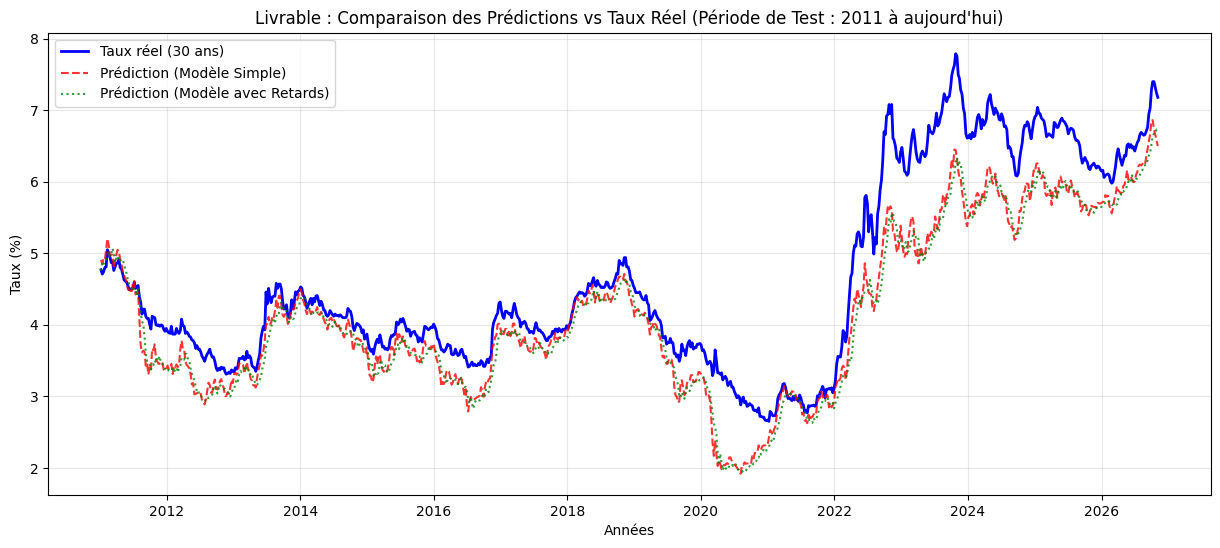

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Taux réel (30 ans)', color='blue', linewidth=2)
plt.plot(y_test.index, y_pred_simple, label='Prédiction (Modèle Simple)', color='red', linestyle='--', alpha=0.8)
plt.plot(y_test.index, y_pred_retards, label='Prédiction (Modèle avec Retards)', color='green', linestyle=':', alpha=0.8)

plt.title('Livrable : Comparaison des Prédictions vs Taux Réel (Période de Test : 2011 à aujourd\'hui)')
plt.xlabel('Années')
plt.ylabel('Taux (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Conclusion : Quelle part des variations s'explique par le taux à 10 ans ?

D'après notre modèle de régression linéaire simple, le taux à 10 ans explique environ **78.55%** (R² = 0.7855) des variations du taux hypothécaire à 30 ans.

L'ajout de retards (le taux à 10 ans de la semaine précédente et d'il y a 4 semaines) n'améliore pas la prédiction (R² descend à 0.76). Cela montre que le marché hypothécaire réagit très rapidement (quasi-instantanément) aux mouvements du taux à 10 ans de la même semaine.

## Limites et Risques (Analyse Critique)

1. **Corrélation n'est pas causalité :** Une forte corrélation ne signifie pas que le taux à 10 ans *force* le taux à 30 ans. Les deux sont influencés par la politique monétaire de la Banque Centrale (la Fed) et les anticipations d'inflation.
2. **Le Spread de crédit (Marge des banques) :** Le graphique des prédictions montre que notre modèle sous-estime le taux réel lors de la remontée des taux en 2022-2023. Cela s'explique par le **spread de crédit** : les banques ont augmenté leur marge pour couvrir les risques (inflation, risque de défaut), ce qui est invisible dans notre modèle basé uniquement sur le taux à 10 ans.
3. **Stabilité temporelle :** Le modèle est entraîné sur la période 1971-2010. La relation entre les taux a pu changer après 2010 (période de taux zéro), ce qui introduit un risque d'instabilité.

## Livrables

- **Notebook :** Ce document contient l'intégralité du code (nettoyage, feature engineering, modélisation, évaluation).
- **Graphique de détection superposée :** Le graphique ci-dessus montre la superposition des prédictions de nos modèles avec le taux réel sur la période de test (2011 à aujourd'hui). Le modèle suit parfaitement la tendance, avec un décalage visible lors des chocs récents (post-2020).